# AQI Forecasting Project
## 01 — Raw Data Inspection

### Objective
Understand the original hourly air-quality dataset before making any
changes.

### Dataset
hourly_air_quality_raw.csv

### Inspection areas
1. Dataset structure and data types
2. Missing values
3. Duplicate observations
4. Timestamp validity
5. Station-wise coverage
6. Hourly continuity and gaps
7. Numeric distributions and suspicious values

The original dataset must remain unchanged.

In [3]:
# Imports and configuration

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = PROJECT_DIR.parent / "hourly_air_quality_raw.csv"

print("Project directory:", PROJECT_DIR)
print("Raw dataset:", RAW_FILE)
print("File exists:", RAW_FILE.exists())

Project directory: C:\Users\anshu\Desktop\ML project\aqi-intelligence\aqi-intelligence\datanew\aqi_rebuild
Raw dataset: C:\Users\anshu\Desktop\ML project\aqi-intelligence\aqi-intelligence\datanew\hourly_air_quality_raw.csv
File exists: True


In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Load original dataset

df = pd.read_csv(RAW_FILE, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (190514, 19)


,observed_at,location_id,station_name,candidate_station,region,latitude,longitude,co,no,no2,nox,o3,pm10,pm25,relative_humidity,so2,temperature,wind_direction,wind_speed
0,2025-02-18 19:30:00+00:00,5613,"ITO, New Delhi - CPCB",ITO,Central Delhi,28.63,77.24,1.76,21.80,78.20,0.06,8.70,152.00,102.00,NaN,15.50,NaN,NaN,NaN
1,2025-02-18 20:30:00+00:00,5613,"ITO, New Delhi - CPCB",ITO,Central Delhi,28.63,77.24,1.74,29.00,121.00,0.09,8.00,143.00,94.00,NaN,15.80,NaN,NaN,NaN
2,2025-02-18 21:30:00+00:00,5613,"ITO, New Delhi - CPCB",ITO,Central Delhi,28.63,77.24,1.50,26.90,103.00,0.08,7.75,137.00,84.30,NaN,15.80,NaN,NaN,NaN
3,2025-02-18 22:30:00+00:00,5613,"ITO, New Delhi - CPCB",ITO,Central Delhi,28.63,77.24,1.85,28.70,111.00,0.08,8.10,173.00,106.00,NaN,8.40,NaN,NaN,NaN
4,2025-02-18 23:30:00+00:00,5613,"ITO, New Delhi - CPCB",ITO,Central Delhi,28.63,77.24,2.01,33.90,141.00,0.10,8.05,170.00,110.00,NaN,7.95,NaN,NaN,NaN


In [5]:
# Dataset structure

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Missing %": (df.isna().mean() * 100).round(2).values,
    "Unique Values": df.nunique().values
}))

Rows: 190514
Columns: 19


,Column,Data Type,Missing Values,Missing %,Unique Values
0,observed_at,str,0,0.00,14214
1,location_id,int64,0,0.00,15
2,station_name,str,0,0.00,15
3,candidate_station,str,0,0.00,15
4,region,str,0,0.00,5
5,latitude,float64,0,0.00,15
6,longitude,float64,0,0.00,15
7,co,float64,9147,4.80,1818
8,no,float64,13186,6.92,1780
9,no2,float64,26512,13.92,1595


## 2. Missing Value Analysis

We will investigate:
1. Missing values by column.
2. Percentage of missing values.
3. Whether missingness is concentrated in particular stations.

This will help us decide an appropriate missing-data strategy later.

In [6]:
# Missing value summary

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
wind_direction,35319,18.54
so2,28694,15.06
wind_speed,27824,14.60
no2,26512,13.92
relative_humidity,26164,13.73
temperature,26117,13.71
o3,17892,9.39
pm25,14039,7.37
no,13186,6.92
nox,12536,6.58


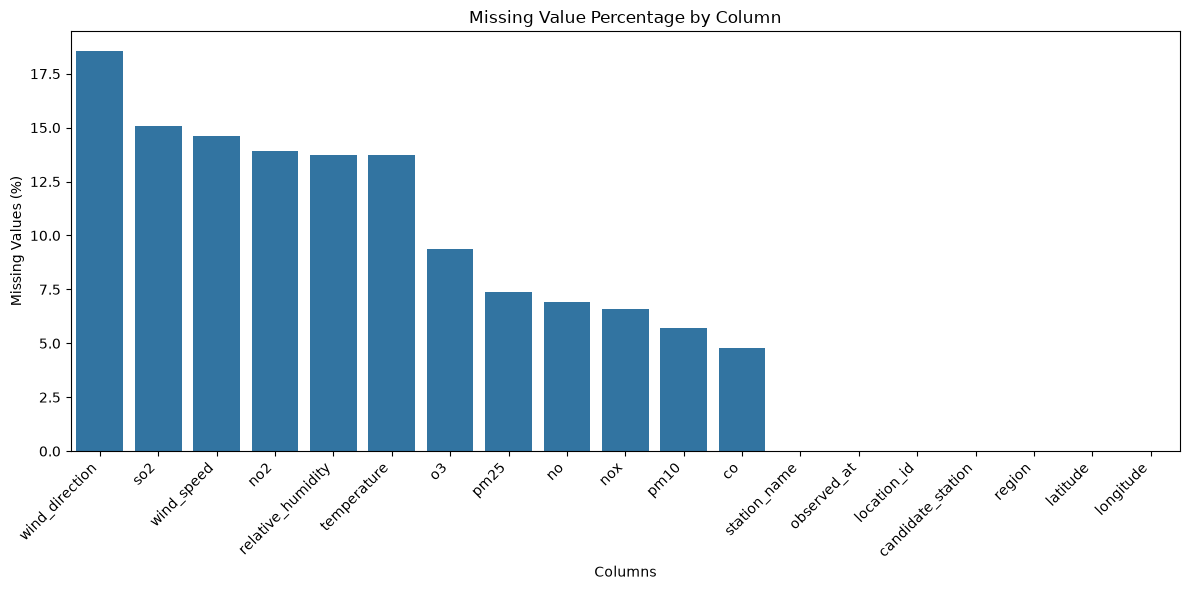

In [7]:
# Missing values by column

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary["Missing_Percentage"]
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Missing Values (%)")
plt.xlabel("Columns")
plt.title("Missing Value Percentage by Column")
plt.tight_layout()
plt.show()

In [8]:
# Missing values by station

station_missing = (
    df.groupby("station_name")[[
        "co", "no", "no2", "nox", "o3",
        "pm10", "pm25", "relative_humidity",
        "so2", "temperature", "wind_direction",
        "wind_speed"
    ]]
    .apply(lambda x: x.isnull().mean() * 100)
    .round(2)
)

display(station_missing)

,co,no,no2,nox,o3,pm10,pm25,relative_humidity,so2,temperature,wind_direction,wind_speed
station_name,,,,,,,,,,,,
"Alipur, Delhi - DPCC",1.75,0.73,0.85,0.58,1.74,1.64,1.35,3.96,1.46,3.21,3.22,14.23
"Anand Vihar, New Delhi - DPCC",1.97,2.67,100.00,1.09,85.44,3.08,1.77,0.53,100.00,0.50,0.64,0.55
"Aya Nagar, New Delhi - IMD",100.00,100.00,100.00,100.00,100.00,0.00,100.00,100.00,100.00,100.00,100.00,100.00
"Bawana, Delhi - DPCC",2.40,2.47,1.78,1.71,0.58,1.38,1.96,0.27,2.04,0.27,1.27,2.77
"Dwarka-Sector 8, Delhi - DPCC",1.31,0.76,0.70,0.70,1.03,0.85,1.21,0.03,1.47,0.03,0.06,0.08
"ITO, New Delhi - CPCB",0.05,0.02,0.03,0.02,0.27,2.97,2.14,100.00,1.19,100.00,100.00,100.00
"Lodhi Road, New Delhi - IMD",37.57,100.00,100.00,100.00,0.45,100.00,100.00,100.00,100.00,100.00,100.00,100.00
"Mandir Marg, New Delhi - DPCC",2.19,2.11,2.59,1.47,2.07,1.71,4.74,0.01,6.67,0.00,3.38,0.01
"Mundka, Delhi - DPCC",1.12,0.66,0.24,0.32,3.43,1.16,1.26,0.59,2.21,1.10,1.14,0.57


## 3. Station-wise Missing Data Analysis

Overall missing percentages do not show whether missing values
are concentrated in particular monitoring stations.

We will use a heatmap to compare missing-value percentages
across stations and pollutant/weather variables.

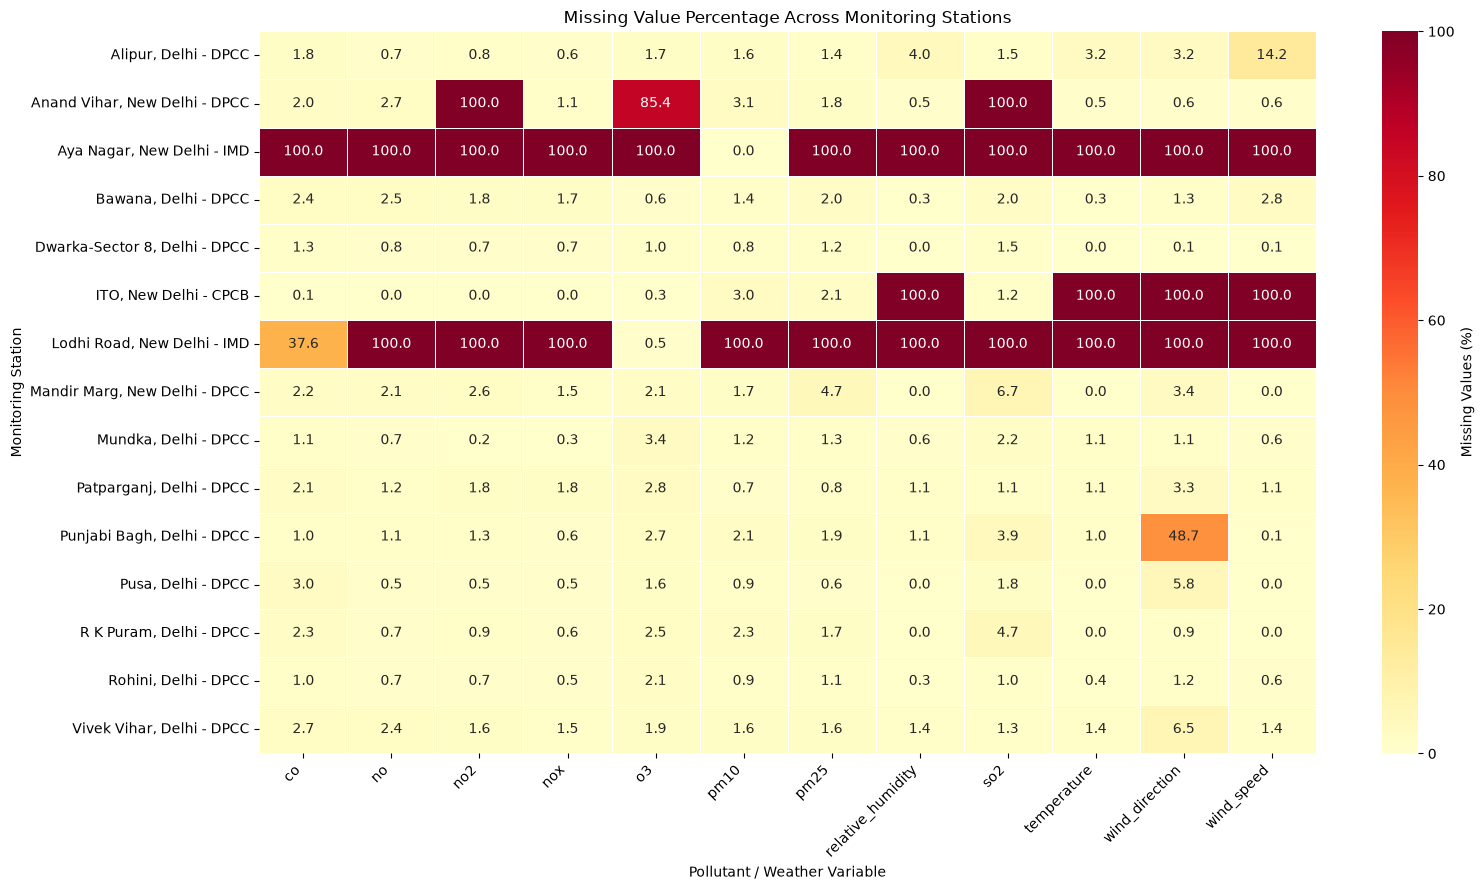

In [9]:
# Station-wise missingness heatmap

plt.figure(figsize=(16, 9))

sns.heatmap(
    station_missing,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Missing Values (%)"}
)

plt.title("Missing Value Percentage Across Monitoring Stations")
plt.xlabel("Pollutant / Weather Variable")
plt.ylabel("Monitoring Station")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# Percentage of available observations per station

station_availability = 100 - station_missing

display(station_availability.round(2))

,co,no,no2,nox,o3,pm10,pm25,relative_humidity,so2,temperature,wind_direction,wind_speed
station_name,,,,,,,,,,,,
"Alipur, Delhi - DPCC",98.25,99.27,99.15,99.42,98.26,98.36,98.65,96.04,98.54,96.79,96.78,85.77
"Anand Vihar, New Delhi - DPCC",98.03,97.33,0.00,98.91,14.56,96.92,98.23,99.47,0.00,99.50,99.36,99.45
"Aya Nagar, New Delhi - IMD",0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00
"Bawana, Delhi - DPCC",97.60,97.53,98.22,98.29,99.42,98.62,98.04,99.73,97.96,99.73,98.73,97.23
"Dwarka-Sector 8, Delhi - DPCC",98.69,99.24,99.30,99.30,98.97,99.15,98.79,99.97,98.53,99.97,99.94,99.92
"ITO, New Delhi - CPCB",99.95,99.98,99.97,99.98,99.73,97.03,97.86,0.00,98.81,0.00,0.00,0.00
"Lodhi Road, New Delhi - IMD",62.43,0.00,0.00,0.00,99.55,0.00,0.00,0.00,0.00,0.00,0.00,0.00
"Mandir Marg, New Delhi - DPCC",97.81,97.89,97.41,98.53,97.93,98.29,95.26,99.99,93.33,100.00,96.62,99.99
"Mundka, Delhi - DPCC",98.88,99.34,99.76,99.68,96.57,98.84,98.74,99.41,97.79,98.90,98.86,99.43


In [11]:
# Number of available PM2.5 observations per station

pm25_availability = (
    df.groupby("station_name")["pm25"]
    .agg(
        Total_Readings="size",
        Available_Readings="count"
    )
)

pm25_availability["Available_Percentage"] = (
    pm25_availability["Available_Readings"]
    / pm25_availability["Total_Readings"] * 100
).round(2)

display(pm25_availability.sort_values(
    "Available_Percentage",
    ascending=False
))

,Total_Readings,Available_Readings,Available_Percentage
station_name,,,
"Pusa, Delhi - DPCC",13888,13801,99.37
"Patparganj, Delhi - DPCC",13784,13670,99.17
"Rohini, Delhi - DPCC",14057,13910,98.95
"Dwarka-Sector 8, Delhi - DPCC",13919,13750,98.79
"Mundka, Delhi - DPCC",13919,13744,98.74
"Alipur, Delhi - DPCC",13506,13323,98.65
"Vivek Vihar, Delhi - DPCC",13769,13549,98.40
"R K Puram, Delhi - DPCC",13727,13489,98.27
"Anand Vihar, New Delhi - DPCC",13736,13493,98.23


## Observations — Missing Value Analysis

1. The dataset contains 190,514 rows and 19 columns.
2. Missing values are concentrated in pollutant and weather variables.
3. Wind direction has the highest overall missing percentage (18.54%).
4. Missingness is not uniformly distributed across stations.
5. Aya Nagar and Lodhi Road have 100% missing PM2.5 values.
6. The remaining 13 stations have PM2.5 availability between
   95.26% and 99.37%.
7. ITO has complete missingness in relative humidity,
   temperature, wind direction and wind speed.

### Preliminary decisions

- Preserve the original raw dataset.
- Do not blindly apply global mean imputation.
- Investigate missingness by station and time.
- Exclude stations without PM2.5 observations from
  PM2.5-based model training unless a valid alternative
  target source becomes available.
- Do not remove stations or observations yet.

## 4. Duplicate Record Analysis

We will check:
1. Exact duplicate rows.
2. Duplicate station and timestamp combinations.

A station should normally have only one observation
for a particular timestamp.

In [12]:
# Check exact duplicate rows

exact_duplicates = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

Exact duplicate rows: 0


In [13]:
# Check duplicate station-timestamp combinations

station_time_duplicates = df.duplicated(
    subset=["location_id", "observed_at"]
).sum()

print(
    "Duplicate station-timestamp combinations:",
    station_time_duplicates
)

Duplicate station-timestamp combinations: 0


In [15]:
# Display duplicate station-timestamp records

duplicate_records = df[
    df.duplicated(
        subset=["location_id", "observed_at"],
        keep=False
    )
].sort_values(["location_id", "observed_at"])

display(duplicate_records.head(20))

,observed_at,location_id,station_name,candidate_station,region,latitude,longitude,co,no,no2,nox,o3,pm10,pm25,relative_humidity,so2,temperature,wind_direction,wind_speed


## Observations — Duplicate Analysis

1. No exact duplicate rows were found.
2. No duplicate (location_id, observed_at) combinations were found.
3. Each station has at most one record for a given timestamp.

### Conclusion
No duplicate removal is required at this stage.
The original dataset remains unchanged.

## 5. Timestamp Validation

We will investigate:
1. Convert observed_at into datetime format.
2. Check invalid timestamps.
3. Identify the dataset's date range.
4. Check timestamp alignment and timezone.

In [16]:
# Convert timestamps into datetime format

df["observed_at"] = pd.to_datetime(
    df["observed_at"],
    utc=True,
    errors="coerce"
)

print("Invalid timestamps:", df["observed_at"].isna().sum())

print("Earliest timestamp:", df["observed_at"].min())
print("Latest timestamp:", df["observed_at"].max())

print("Unique timestamps:", df["observed_at"].nunique())

display(df[["observed_at", "station_name"]].head())

Invalid timestamps: 0
Earliest timestamp: 2025-02-18 19:30:00+00:00
Latest timestamp: 2026-11-14 11:30:00+00:00
Unique timestamps: 14214


,observed_at,station_name
0,2025-02-18 19:30:00+00:00,"ITO, New Delhi - CPCB"
1,2025-02-18 20:30:00+00:00,"ITO, New Delhi - CPCB"
2,2025-02-18 21:30:00+00:00,"ITO, New Delhi - CPCB"
3,2025-02-18 22:30:00+00:00,"ITO, New Delhi - CPCB"
4,2025-02-18 23:30:00+00:00,"ITO, New Delhi - CPCB"


In [17]:
# Convert UTC timestamps to Indian Standard Time

df["observed_at_ist"] = df["observed_at"].dt.tz_convert(
    "Asia/Kolkata"
)

print("Sample UTC timestamps:")
display(df["observed_at"].head())

print("Sample IST timestamps:")
display(df["observed_at_ist"].head())

Sample UTC timestamps:


0   2025-02-18 19:30:00+00:00
1   2025-02-18 20:30:00+00:00
2   2025-02-18 21:30:00+00:00
3   2025-02-18 22:30:00+00:00
4   2025-02-18 23:30:00+00:00
Name: observed_at, dtype: datetime64[us, UTC]

Sample IST timestamps:


0   2025-02-19 01:00:00+05:30
1   2025-02-19 02:00:00+05:30
2   2025-02-19 03:00:00+05:30
3   2025-02-19 04:00:00+05:30
4   2025-02-19 05:00:00+05:30
Name: observed_at_ist, dtype: datetime64[us, Asia/Kolkata]

## 6. Hourly Timestamp Alignment

Our project uses hourly air-quality observations.

We need to verify that timestamps:
1. Fall exactly on hourly boundaries.
2. Have zero minutes and seconds.
3. Follow a consistent hourly sequence.

This is important because lag features and future forecasting
depend on correctly ordered hourly observations.

In [18]:
# Check minute and second components

timestamp_alignment = pd.DataFrame({
    "Minute_Values": sorted(
        df["observed_at_ist"].dt.minute.unique()
    ),
    "Second_Values": sorted(
        df["observed_at_ist"].dt.second.unique()
    )
})

display(timestamp_alignment)

,Minute_Values,Second_Values
0,0,0


In [19]:
print(
    "Unique minute values:",
    sorted(df["observed_at_ist"].dt.minute.unique())
)

print(
    "Unique second values:",
    sorted(df["observed_at_ist"].dt.second.unique())
)

Unique minute values: [np.int32(0)]
Unique second values: [np.int32(0)]


In [20]:
# Check timestamp intervals for each station

interval_results = []

for station, group in df.groupby("station_name"):

    timestamps = (
        group["observed_at_ist"]
        .sort_values()
        .drop_duplicates()
    )

    intervals = timestamps.diff().dropna()

    interval_results.append({
        "Station": station,
        "Median_Interval_Hours": (
            intervals.median().total_seconds() / 3600
        ),
        "Minimum_Interval_Hours": (
            intervals.min().total_seconds() / 3600
        ),
        "Maximum_Interval_Hours": (
            intervals.max().total_seconds() / 3600
        )
    })

interval_summary = pd.DataFrame(interval_results)

display(interval_summary.round(2))

,Station,Median_Interval_Hours,Minimum_Interval_Hours,Maximum_Interval_Hours
0,"Alipur, Delhi - DPCC",1.00,1.00,243.00
1,"Anand Vihar, New Delhi - DPCC",1.00,1.00,243.00
2,"Aya Nagar, New Delhi - IMD",1.00,1.00,112.00
3,"Bawana, Delhi - DPCC",1.00,1.00,243.00
4,"Dwarka-Sector 8, Delhi - DPCC",1.00,1.00,243.00
5,"ITO, New Delhi - CPCB",1.00,1.00,243.00
6,"Lodhi Road, New Delhi - IMD",1.00,1.00,1458.00
7,"Mandir Marg, New Delhi - DPCC",1.00,1.00,243.00
8,"Mundka, Delhi - DPCC",1.00,1.00,243.00
9,"Patparganj, Delhi - DPCC",1.00,1.00,243.00


## 7. Hourly Coverage and Missing Intervals

We will calculate:
1. First and last observation for each station.
2. Expected hourly observations.
3. Actual hourly observations.
4. Missing hourly observations.
5. Percentage of hourly coverage.

Coverage is calculated between each station's first and last
recorded timestamps.

In [21]:
# Calculate hourly coverage for every station

coverage_results = []

for station, group in df.groupby("station_name"):

    timestamps = (
        group["observed_at_ist"]
        .dropna()
        .sort_values()
        .drop_duplicates()
    )

    expected_hours = pd.date_range(
        start=timestamps.min(),
        end=timestamps.max(),
        freq="h"
    )

    actual_hours = pd.DatetimeIndex(timestamps)

    missing_hours = expected_hours.difference(actual_hours)

    expected_count = len(expected_hours)
    actual_count = len(actual_hours)

    coverage_results.append({
        "Station": station,
        "First_Observation": timestamps.min(),
        "Last_Observation": timestamps.max(),
        "Expected_Hours": expected_count,
        "Actual_Hours": actual_count,
        "Missing_Hours": len(missing_hours),
        "Coverage_Percentage": round(
            actual_count / expected_count * 100, 2
        )
    })

coverage_df = pd.DataFrame(coverage_results)

display(
    coverage_df.sort_values(
        "Coverage_Percentage",
        ascending=False
    )
)

,Station,First_Observation,Last_Observation,Expected_Hours,Actual_Hours,Missing_Hours,Coverage_Percentage
13,"Rohini, Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 15:00:00+05:30,15207,14057,1150,92.44
5,"ITO, New Delhi - CPCB",2025-02-19 01:00:00+05:30,2026-11-14 17:00:00+05:30,15209,13924,1285,91.55
4,"Dwarka-Sector 8, Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 17:00:00+05:30,15209,13919,1290,91.52
8,"Mundka, Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 17:00:00+05:30,15209,13919,1290,91.52
3,"Bawana, Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 14:00:00+05:30,15206,13894,1312,91.37
11,"Pusa, Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 17:00:00+05:30,15209,13888,1321,91.31
9,"Patparganj, Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 16:00:00+05:30,15208,13784,1424,90.64
14,"Vivek Vihar, Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 16:00:00+05:30,15208,13769,1439,90.54
7,"Mandir Marg, New Delhi - DPCC",2025-02-19 01:00:00+05:30,2026-11-14 17:00:00+05:30,15209,13765,1444,90.51
1,"Anand Vihar, New Delhi - DPCC",2025-02-19 03:00:00+05:30,2026-11-14 16:00:00+05:30,15206,13736,1470,90.33


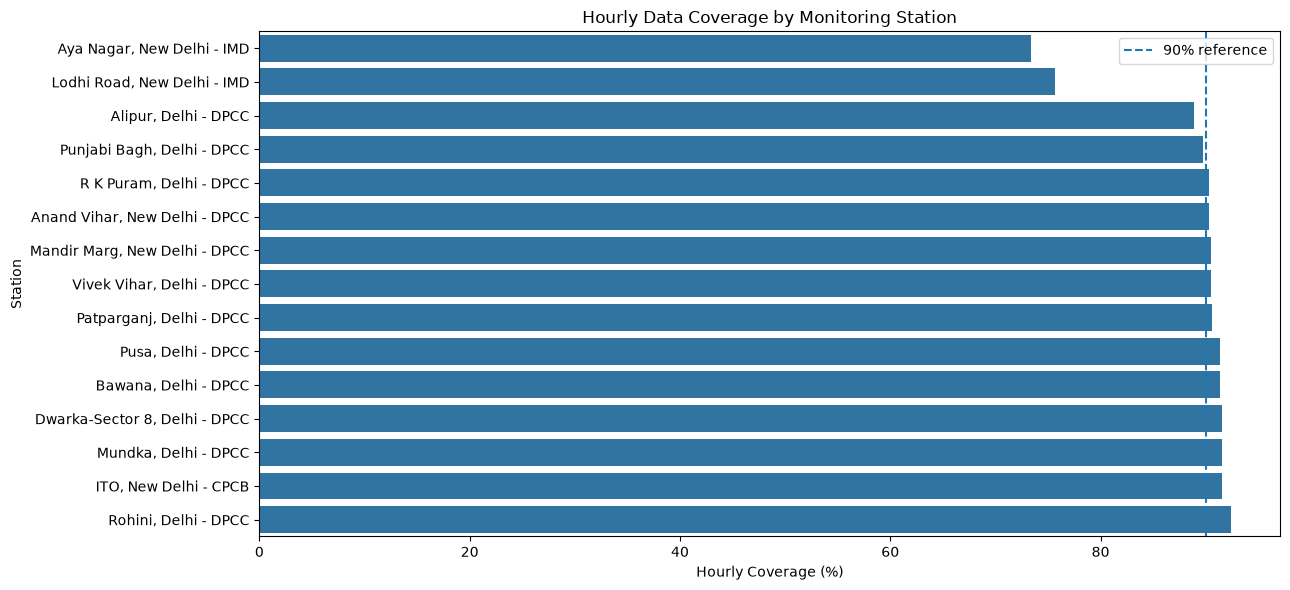

In [22]:
# Plot hourly coverage by station

plt.figure(figsize=(13, 6))

sns.barplot(
    data=coverage_df.sort_values("Coverage_Percentage"),
    x="Coverage_Percentage",
    y="Station"
)

plt.axvline(
    90,
    linestyle="--",
    label="90% reference"
)

plt.xlabel("Hourly Coverage (%)")
plt.ylabel("Station")
plt.title("Hourly Data Coverage by Monitoring Station")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Investigation of Longest Data Gaps

We will identify consecutive missing hourly intervals
for each monitoring station.

The purpose is to:
1. Find the longest gaps.
2. Identify when these gaps occurred.
3. Check whether multiple stations experienced
   outages during the same period.

This will help us distinguish isolated missing observations
from prolonged data collection interruptions.

In [23]:
# Identify gaps between consecutive observations

gap_records = []

for station, group in df.groupby("station_name"):

    timestamps = (
        group["observed_at_ist"]
        .dropna()
        .sort_values()
        .drop_duplicates()
        .reset_index(drop=True)
    )

    intervals = timestamps.diff()

    for i in range(1, len(timestamps)):

        gap_hours = intervals.iloc[i].total_seconds() / 3600

        if gap_hours > 1:

            gap_records.append({
                "Station": station,
                "Gap_Start": timestamps.iloc[i - 1],
                "Gap_End": timestamps.iloc[i],
                "Missing_Hours": int(gap_hours - 1),
                "Interval_Hours": int(gap_hours)
            })

gaps_df = pd.DataFrame(gap_records)

print("Total gaps found:", len(gaps_df))

display(
    gaps_df.sort_values(
        "Missing_Hours",
        ascending=False
    ).head(30)
)

Total gaps found: 3249


,Station,Gap_Start,Gap_End,Missing_Hours,Interval_Hours
1294,"Lodhi Road, New Delhi - IMD",2025-07-27 19:00:00+05:30,2025-09-26 13:00:00+05:30,1457,1458
897,"Dwarka-Sector 8, Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
1761,"Mundka, Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
2891,"Rohini, Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
365,"Anand Vihar, New Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
3120,"Vivek Vihar, Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
103,"Alipur, Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
1489,"Mandir Marg, New Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
2215,"Punjabi Bagh, Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243
1991,"Patparganj, Delhi - DPCC",2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,243


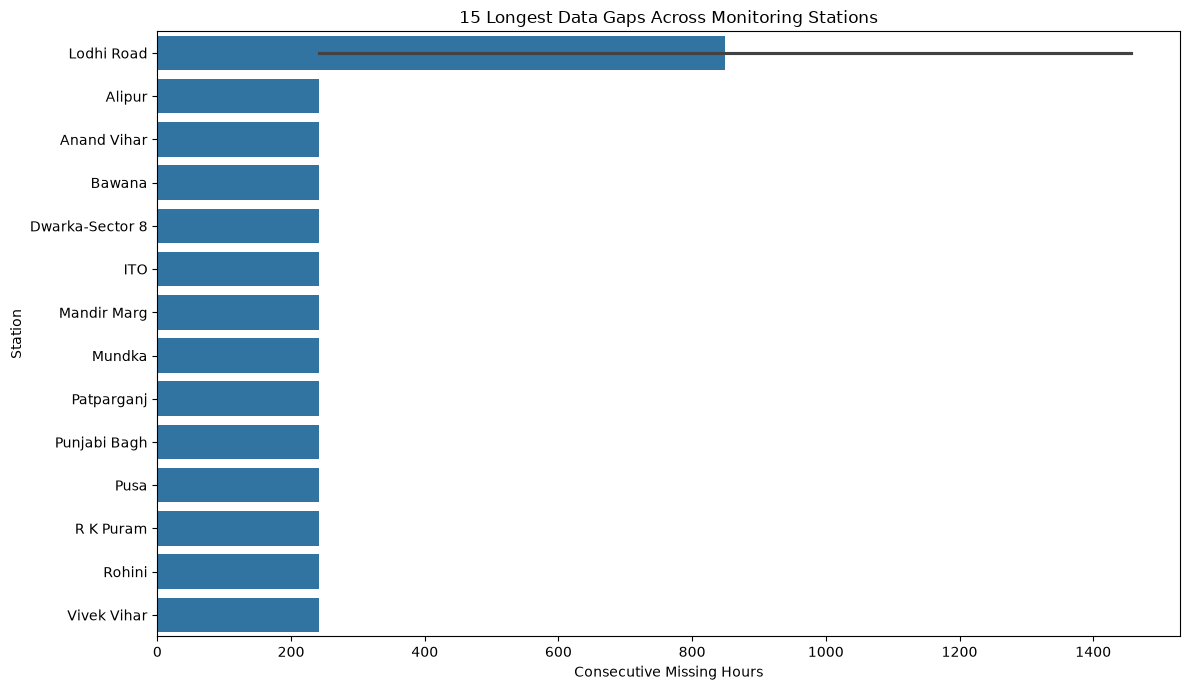

In [24]:
# Top 15 longest gaps across all stations

top_gaps = gaps_df.nlargest(15, "Missing_Hours").copy()

top_gaps["Station_Short"] = (
    top_gaps["Station"].str.split(",").str[0]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_gaps,
    x="Missing_Hours",
    y="Station_Short"
)

plt.xlabel("Consecutive Missing Hours")
plt.ylabel("Station")
plt.title("15 Longest Data Gaps Across Monitoring Stations")
plt.tight_layout()
plt.show()

## 9. Identifying Common Data Outages

We will group gaps by their start and end timestamps.

This will help identify periods when multiple monitoring
stations simultaneously stopped reporting observations.

We will investigate whether the missing intervals represent
station-specific interruptions or broader data collection outages.

In [25]:
# Group identical gap intervals across stations

common_outages = (
    gaps_df.groupby(
        ["Gap_Start", "Gap_End", "Missing_Hours"]
    )
    .agg(
        Affected_Stations=("Station", "nunique"),
        Station_Names=("Station", lambda x: list(x))
    )
    .reset_index()
    .sort_values(
        ["Affected_Stations", "Missing_Hours"],
        ascending=False
    )
)

display(common_outages.head(20))

,Gap_Start,Gap_End,Missing_Hours,Affected_Stations,Station_Names
247,2025-06-21 07:00:00+05:30,2025-06-21 13:00:00+05:30,5,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
270,2025-07-02 15:00:00+05:30,2025-07-02 18:00:00+05:30,2,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
182,2025-05-20 19:00:00+05:30,2025-05-20 21:00:00+05:30,1,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
244,2025-06-18 17:00:00+05:30,2025-06-18 19:00:00+05:30,1,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
558,2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,14,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
575,2026-02-03 14:00:00+05:30,2026-02-04 07:00:00+05:30,16,14,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
601,2026-02-18 21:00:00+05:30,2026-02-19 13:00:00+05:30,15,14,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
102,2025-04-15 18:00:00+05:30,2025-04-16 09:00:00+05:30,14,14,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
632,2026-03-09 23:00:00+05:30,2026-03-10 13:00:00+05:30,13,14,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
214,2025-06-03 03:00:00+05:30,2025-06-03 13:00:00+05:30,9,14,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."


In [26]:
# Show only outages affecting at least 3 stations

major_outages = common_outages[
    common_outages["Affected_Stations"] >= 3
].copy()

print("Common outage events:", len(major_outages))

display(major_outages)

Common outage events: 239


,Gap_Start,Gap_End,Missing_Hours,Affected_Stations,Station_Names
247,2025-06-21 07:00:00+05:30,2025-06-21 13:00:00+05:30,5,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
270,2025-07-02 15:00:00+05:30,2025-07-02 18:00:00+05:30,2,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
182,2025-05-20 19:00:00+05:30,2025-05-20 21:00:00+05:30,1,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
244,2025-06-18 17:00:00+05:30,2025-06-18 19:00:00+05:30,1,15,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
558,2026-01-10 17:00:00+05:30,2026-01-20 20:00:00+05:30,242,14,"[Alipur, Delhi - DPCC, Anand Vihar, New Delhi ..."
...,...,...,...,...,...
695,2026-04-18 19:00:00+05:30,2026-04-18 21:00:00+05:30,1,3,"[ITO, New Delhi - CPCB, Lodhi Road, New Delhi ..."
826,2026-06-18 17:00:00+05:30,2026-06-18 19:00:00+05:30,1,3,"[Mandir Marg, New Delhi - DPCC, Patparganj, De..."
937,2026-08-06 17:00:00+05:30,2026-08-06 19:00:00+05:30,1,3,"[Anand Vihar, New Delhi - DPCC, Mandir Marg, N..."
942,2026-08-06 23:00:00+05:30,2026-08-07 01:00:00+05:30,1,3,"[Dwarka-Sector 8, Delhi - DPCC, Pusa, Delhi - ..."


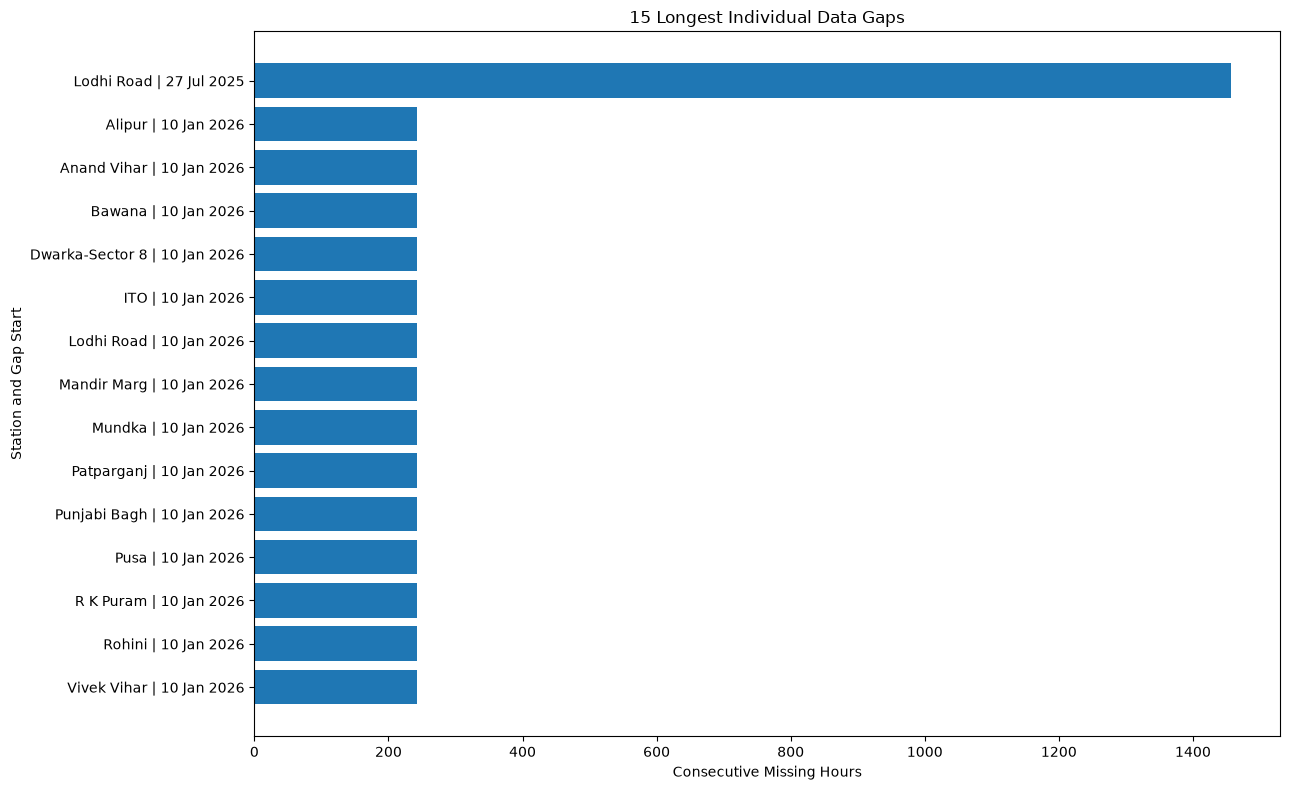

In [27]:
# Plot individual longest gaps without aggregation

top_gaps = gaps_df.nlargest(
    15, "Missing_Hours"
).copy()

top_gaps["Gap_Label"] = (
    top_gaps["Station"].str.split(",").str[0]
    + " | "
    + top_gaps["Gap_Start"].dt.strftime("%d %b %Y")
)

plt.figure(figsize=(13, 8))

plt.barh(
    top_gaps["Gap_Label"],
    top_gaps["Missing_Hours"]
)

plt.xlabel("Consecutive Missing Hours")
plt.ylabel("Station and Gap Start")
plt.title("15 Longest Individual Data Gaps")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Numeric Distribution and Outlier Inspection

We will investigate the distributions of pollutant and
weather variables.

The analysis will include:
1. Descriptive statistics.
2. Histograms.
3. Boxplots.
4. Potential extreme values.

Extreme values will be flagged for investigation,
not automatically removed.

In [28]:
# Descriptive statistics of numeric variables

numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

numeric_summary = df[numeric_columns].describe().T

numeric_summary["Missing_Percentage"] = (
    df[numeric_columns].isnull().mean() * 100
).round(2)

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max,Missing_Percentage
location_id,190514.00,5864.18,3380.07,17.00,5613.00,6931.00,6960.00,10831.00,0.00
latitude,190514.00,28.66,0.07,28.47,28.62,28.65,28.68,28.82,0.00
longitude,190514.00,77.18,0.09,77.05,77.12,77.15,77.24,77.32,0.00
co,181367.00,1.21,0.96,0.00,0.66,0.97,1.44,9.84,4.80
no,177328.00,21.12,40.55,0.00,3.30,6.98,20.30,499.00,6.92
no2,164002.00,40.87,29.95,0.00,19.30,33.60,55.20,445.00,13.92
nox,177978.00,0.04,0.04,0.00,0.01,0.03,0.05,1.94,6.58
o3,172622.00,30.23,34.33,0.00,7.78,17.30,39.50,494.00,9.39
pm10,179596.00,196.83,139.95,0.00,98.50,162.00,257.00,1790.00,5.73
pm25,176475.00,88.76,87.33,0.00,33.30,57.50,112.00,997.00,7.37


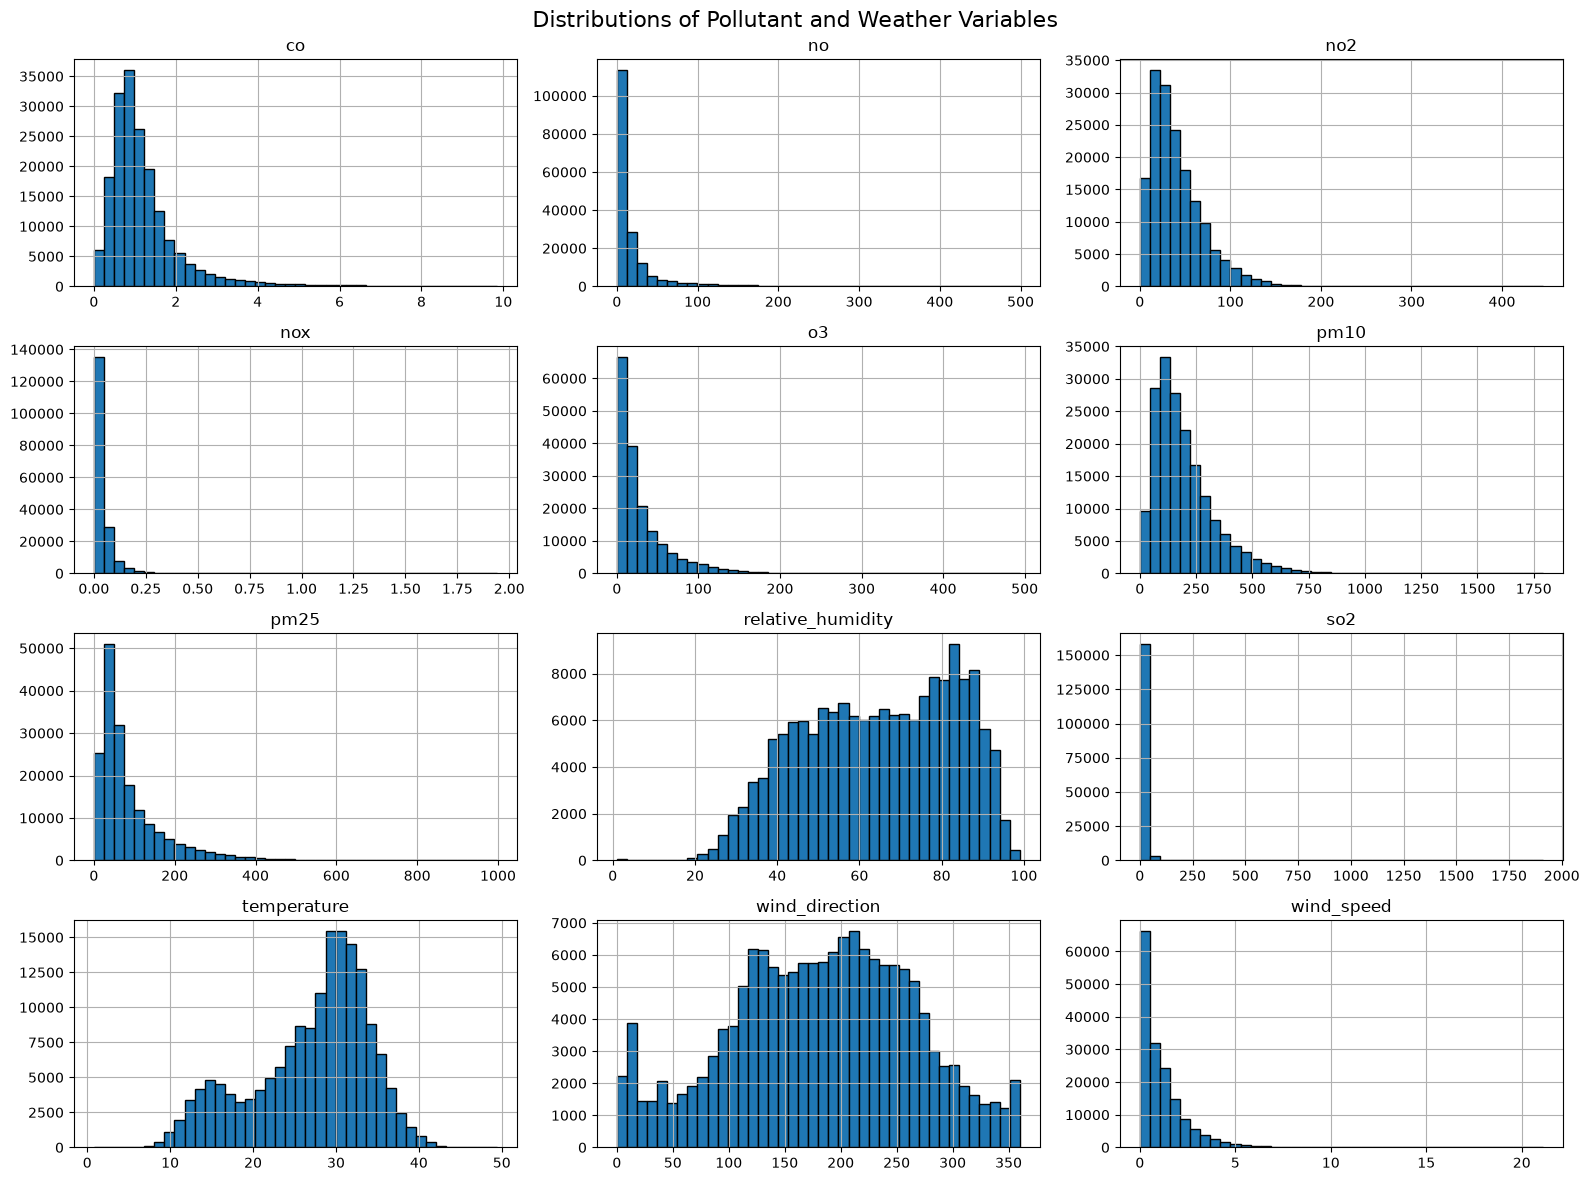

In [29]:
# Distribution plots for pollutant and weather variables

measurement_columns = [
    "co", "no", "no2", "nox", "o3",
    "pm10", "pm25", "relative_humidity",
    "so2", "temperature", "wind_direction",
    "wind_speed"
]

df[measurement_columns].hist(
    bins=40,
    figsize=(16, 12),
    layout=(4, 3),
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Pollutant and Weather Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 11. Potential Outlier Detection Using IQR

We will use the Interquartile Range (IQR) method to identify
potentially extreme observations.

For each measurement variable:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 * IQR
Upper Bound = Q3 + 1.5 * IQR

These observations will be flagged for further investigation.
They will not be automatically removed.

In [30]:
# IQR-based potential outlier analysis

outlier_results = []

for col in measurement_columns:

    series = df[col].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = series[
        (series < lower_bound) |
        (series > upper_bound)
    ]

    outlier_results.append({
        "Variable": col,
        "Lower_Bound": round(lower_bound, 3),
        "Upper_Bound": round(upper_bound, 3),
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": round(
            len(outliers) / len(series) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.sort_values(
        "Outlier_Percentage",
        ascending=False
    )
)

,Variable,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
1,no,-22.20,45.80,19352,10.91
3,nox,-0.04,0.10,13668,7.68
4,o3,-39.80,87.08,13063,7.57
6,pm25,-84.75,230.05,13294,7.53
0,co,-0.50,2.60,11979,6.60
8,so2,-10.72,35.08,8725,5.39
11,wind_speed,-1.62,3.50,8100,4.98
5,pm10,-139.25,494.75,7329,4.08
2,no2,-34.55,109.05,5441,3.32
9,temperature,9.10,45.90,412,0.25


In [31]:
# PM2.5 percentile analysis

pm25_percentiles = df["pm25"].describe(
    percentiles=[
        0.50, 0.75, 0.90, 0.95, 0.99, 0.999
    ]
)

display(pm25_percentiles)

count   176475.00
mean        88.76
std         87.33
min          0.00
50%         57.50
75%        112.00
90%        201.00
95%        272.00
99%        421.00
99.9%      606.53
max        997.00
Name: pm25, dtype: float64

In [32]:
# Inspect the 20 highest PM2.5 readings

pm25_extremes = (
    df.nlargest(20, "pm25")[
        [
            "observed_at_ist",
            "station_name",
            "pm25",
            "pm10",
            "no2",
            "so2",
            "temperature"
        ]
    ]
)

display(pm25_extremes)

,observed_at_ist,station_name,pm25,pm10,no2,so2,temperature
33197,2025-10-21 06:00:00+05:30,"Pusa, Delhi - DPCC",997.00,1350.00,24.70,20.40,25.00
190381,2026-11-09 03:00:00+05:30,"Punjabi Bagh, Delhi - DPCC",993.00,NaN,95.40,102.00,27.60
182155,2025-10-21 00:00:00+05:30,"Punjabi Bagh, Delhi - DPCC",970.00,NaN,58.30,12.90,27.20
5549,2025-10-21 06:00:00+05:30,"ITO, New Delhi - CPCB",967.00,1220.00,71.20,21.70,NaN
13792,2026-11-09 06:00:00+05:30,"ITO, New Delhi - CPCB",942.00,NaN,45.50,36.20,NaN
68958,2026-11-08 22:00:00+05:30,"Patparganj, Delhi - DPCC",930.00,NaN,93.50,187.00,25.30
148886,2026-11-08 21:00:00+05:30,"R K Puram, Delhi - DPCC",924.00,NaN,40.50,37.10,24.30
101970,2025-10-21 00:00:00+05:30,"Bawana, Delhi - DPCC",920.00,1020.00,40.50,112.00,26.50
33191,2025-10-21 00:00:00+05:30,"Pusa, Delhi - DPCC",910.00,942.00,44.10,60.90,25.10
27556,2026-11-09 05:00:00+05:30,"Mandir Marg, New Delhi - DPCC",879.00,948.00,14.00,66.20,28.90


## 12. Station-wise PM2.5 Distribution

We will compare PM2.5 measurements across monitoring stations.

The analysis will include:
1. Mean and median PM2.5.
2. 95th and 99th percentiles.
3. Maximum observed PM2.5.
4. Number of readings above 500.

This will help identify stations with unusual
PM2.5 distributions or extreme measurements.

In [33]:
# Station-wise PM2.5 statistics

station_pm25_summary = (
    df.groupby("station_name")["pm25"]
    .agg(
        Available_Readings="count",
        Mean="mean",
        Median="median",
        P95=lambda x: x.quantile(0.95),
        P99=lambda x: x.quantile(0.99),
        Maximum="max"
    )
)

station_pm25_summary["Readings_Above_500"] = (
    df.groupby("station_name")["pm25"]
    .apply(lambda x: (x > 500).sum())
)

display(
    station_pm25_summary.round(2)
    .sort_values("Median", ascending=False)
)

,Available_Readings,Mean,Median,P95,P99,Maximum,Readings_Above_500
station_name,,,,,,,
"Anand Vihar, New Delhi - DPCC",13493,100.12,69.50,296.40,458.08,767.00,84
"Bawana, Delhi - DPCC",13621,103.36,68.80,306.00,459.80,920.00,89
"R K Puram, Delhi - DPCC",13489,92.09,61.30,276.00,432.00,924.00,67
"Rohini, Delhi - DPCC",13910,98.16,60.30,312.00,483.00,690.00,120
"Punjabi Bagh, Delhi - DPCC",13386,91.94,59.00,297.00,432.00,993.00,50
"Alipur, Delhi - DPCC",13323,85.57,57.30,247.90,385.56,759.00,27
"Mundka, Delhi - DPCC",13744,94.16,55.80,296.00,445.57,857.00,77
"Mandir Marg, New Delhi - DPCC",13113,73.87,55.00,214.00,333.88,879.00,9
"Dwarka-Sector 8, Delhi - DPCC",13750,83.00,54.30,250.00,360.00,774.00,15


In [34]:
# Count stations with PM2.5 above 500 at each timestamp

extreme_events = (
    df[df["pm25"] > 500]
    .groupby("observed_at_ist")
    .agg(
        Stations_Affected=("station_name", "nunique"),
        Station_Names=("station_name", list),
        Maximum_PM25=("pm25", "max"),
        Mean_PM25=("pm25", "mean")
    )
    .reset_index()
    .sort_values(
        ["Stations_Affected", "Maximum_PM25"],
        ascending=False
    )
)

display(extreme_events.head(20))

,observed_at_ist,Stations_Affected,Station_Names,Maximum_PM25,Mean_PM25
74,2025-11-12 02:00:00+05:30,11,"[ITO, New Delhi - CPCB, Mandir Marg, New Delhi...",690.00,576.45
73,2025-11-12 01:00:00+05:30,11,"[ITO, New Delhi - CPCB, Pusa, Delhi - DPCC, An...",679.00,574.09
75,2025-11-12 03:00:00+05:30,8,"[ITO, New Delhi - CPCB, Patparganj, Delhi - DP...",650.00,574.12
178,2025-12-14 00:00:00+05:30,8,"[ITO, New Delhi - CPCB, Anand Vihar, New Delhi...",638.00,568.88
176,2025-12-13 22:00:00+05:30,7,"[Anand Vihar, New Delhi - DPCC, Patparganj, De...",679.00,586.00
72,2025-11-12 00:00:00+05:30,7,"[ITO, New Delhi - CPCB, Vivek Vihar, Delhi - D...",650.00,573.43
177,2025-12-13 23:00:00+05:30,7,"[Anand Vihar, New Delhi - DPCC, Patparganj, De...",635.00,583.71
167,2025-12-13 10:00:00+05:30,7,"[Anand Vihar, New Delhi - DPCC, Patparganj, De...",616.00,571.57
166,2025-12-13 09:00:00+05:30,7,"[ITO, New Delhi - CPCB, Anand Vihar, New Delhi...",614.00,561.00
26,2025-10-20 23:00:00+05:30,6,"[ITO, New Delhi - CPCB, Mandir Marg, New Delhi...",857.00,704.67
